# Proyek Analisis Data: Bike Share Dataset
- **Nama:** Rafi Geraldy Krisnugraha
- **Email:** raffigerald2018@gmail.com
- **ID Dicoding:** rafigeraldy

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagiamana pengaruh kondisi cuaca dan musim terhadap total penyewaan sepeda harian selama tahun 2011 hingga 2012?
- **Pertanyaan 2:** Bagaimana perbedaan pola penyewaan sepeda antara pengguna kasual dan pengguna terdaftar pada hari kerja dibandingkan dengan hari libur?
- ...

## Import Semua Packages/Library yang Digunakan

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [4]:
# memuat dataset day.csv dan hour.csv
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

# Menampilkan 5 baris pertama untuk memastikan data berhasil dimuat
display(day_df.head())
display(hour_df.head())

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Dataset berhasil dimuat dengan baik ke dalam DataFrame Pandas: day_df mencakup rekaman data penyewaan harian (731 baris) dan hour_df mencakup data penyewaan per jam (17.379 baris)
- Dataset hour_df memiliki 17 kolom (termasuk atribut jam), sedangkan day_df memiliki kolom tanpa variabel jam.
- Struktur awal data sudah mencakup pemisahan kategori pengguna (casual dan registered) serta faktor iklim (season, weathersit, temp, atemp, hum, windspeed) yang siap dianalisis.

### Assessing Data

#### Identifying ... problem

In [6]:
# 1. Memeriksa tipe data dan missing values pada day dan hour df
print("--- Info day_df ---")
day_df.info()

print("\n--- info hour_df ---")
hour_df.info()

# 2. memeriksa jumlah nilai duplikat
print("\nJumlah duplikat day_df:", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

# 3. Memeriksa ringkasan parameter statistik
print("\nRingkasan statistik day_df:")
display(day_df.describe())


--- Info day_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

--- info hour_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- Mengubah tipe data kolom dteday dari object menjadi datetime pada day_df dan hour_df.
- Mengubah nama kolom yang berupa singkatan agar lebih deskriptif (misalnya dteday > date)
- Melakukan mapping nilai numerik pada variabel kategorikal season, year, dan weather_condition menjadi label teks yang intuitif (misal: 1 > 'Spring', 2 > 'Summer')


**Insight:** (Opsional)
- Kedua dataframe tidak memiliki nilai kosong (null/NaN) maupun baris data yang duplikat.
- dteday tersimpan sebagai objeks teks (string), padahal merepresentasikan nilai tanggal (datetima)
- Kolom seperti season dan weathersit menggunakan angka 1-4 yang kurang intuitif saat analisis visual tanpa dokumentasi.

### Cleaning Data

#### Fixing Data Type, Column Names, and Category Mapping problem

In [7]:
# 1. Mengubah tipe data 'dteday' menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mengubah nama kolom agar lebih informatif dan mudah dibaca
day_df.rename(columns={'dteday': 'date',
                       'yr': 'year',
                       'mnth': 'month',
                       'weathersit': 'weather_condition',
                       'hum': 'humidity',
                       'cnt': 'total_count'
                       }, inplace=True)

hour_df.rename(columns={'dteday': 'date',
                        'yr': 'year',
                        'mnth': 'month',
                        'hr': 'hour',
                        'weathersit': 'weather_condition',
                        'hum': 'humidity',
                        'cnt': 'total_count'
                        }, inplace=True)

# 3 Mapping angka numerik menjadi nilai teks deskriptif
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season'] = day_df['season'].map(season_mapping)
hour_df['season'] = hour_df['season'].map(season_mapping)

year_mapping = {0: '2011', 1: '2012'}
day_df['year'] = day_df['year'].map(year_mapping)
hour_df['year'] = hour_df['year'].map(year_mapping)

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/rain',
    4: 'Severe Weather'
    }
day_df['weather_condition'] = day_df['weather_condition'].map(weather_mapping)
hour_df['weather_condition'] = hour_df['weather_condition'].map(weather_mapping)

# Verifikasi hasil pembersihan data
print("--- Info day_df Setelah Cleaning ---")
day_df.info()
display(day_df.head())

--- Info day_df Setelah Cleaning ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   instant            731 non-null    int64         
 1   date               731 non-null    datetime64[ns]
 2   season             731 non-null    object        
 3   year               731 non-null    object        
 4   month              731 non-null    int64         
 5   holiday            731 non-null    int64         
 6   weekday            731 non-null    int64         
 7   workingday         731 non-null    int64         
 8   weather_condition  731 non-null    object        
 9   temp               731 non-null    float64       
 10  atemp              731 non-null    float64       
 11  humidity           731 non-null    float64       
 12  windspeed          731 non-null    float64       
 13  casual             731 non-n

,instant,date,season,year,month,holiday,weekday,workingday,weather_condition,temp,atemp,humidity,windspeed,casual,registered,total_count
0,1,2011-01-01,Spring,2011,1,0,6,0,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,1,0,0,0,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,1,0,1,1,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,1,0,2,1,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,1,0,3,1,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Kolom date (dteday) berhasil diubah menjadi tipe data datetime sehingga mempermudah manipulasi data berbasis waktu.
- Kolom-kolom dengan nama singkatan telah diubah menjadi bentuk kata penuh (date, year, month, humidity, total_count, weather_condition)
- Nilai numerik pada variabel season, year, dan weather_condition telah dipetakan ke bentuk teks deskriptif(misal:'Spring', 'clear/partly cloudy') untuk memperlancar eksplorasi dan pembuatan visualisasi data.

## Exploratory Data Analysis (EDA)

### Explore Data Penyewaan Sepeda (Cuaca, Musim, & Tipe Pengguna)

In [9]:
# 1. Agregasi total penyewaan berdasarkan kondisi cuaca
weather_eda = day_df.groupby('weather_condition').agg({
    'total_count': ['mean', 'max', 'min', 'std']
}).reset_index()
print("--- Rigkasan Penyewaan Berdasarkan Kondisi Cuaca ---")
display(weather_eda)

# 2. Agregasi total penyewaan berdasarkan musim
season_eda = day_df.groupby('season').agg({
    'total_count': ['mean', 'max', 'min', 'std']
}).reset_index()
print("\n--- Rigkasan Penyewaan Berdasarkan Musim ---")
display(season_eda)



--- Rigkasan Penyewaan Berdasarkan Kondisi Cuaca ---


weather_condition  total_count                        
                               mean   max  min          std
0  Clear/Partly Cloudy  4876.786177  8714  431  1879.483989
1      Light Snow/rain  1803.285714  4639   22  1240.284449
2          Mist/Cloudy  4035.862348  8362  605  1809.109918


--- Rigkasan Penyewaan Berdasarkan Musim ---


season  total_count                         
                  mean   max   min          std
0    Fall  5644.303191  8714  1115  1459.800381
1  Spring  2604.132597  7836   431  1399.942119
2  Summer  4992.331522  8362   795  1695.977235
3  Winter  4728.162921  8555    22  1699.615261

**Insight:** (Opsional)
- Penyewaan sepeda mencapai puncaknya pada cuaca cerah/berawan (Clear/Partly Cloudy) dengan rata-rata 4.876 penyewaan/hari, lalu menurun drastis saat cuaca burul (Light Snow/Rain) menjadi rata-rata 1.803 penyewaan/hari
- Musim Gugur (Fall) mencatatkan volume penyewaan tertinggi (rata-rata 5.644 penyewaan/hari), sedangkan Musim Semi (Spring) mencatatkan rata-rata terendah (2.604 penyewaan/hari)
- Pengguna terdaftar (registered) aktif di hari kerja (rata-rata 3.798 penyewaa/hari) untuk kebutuhan mobilitas harian (commuting). Sebaliknya, pengguna kasual meningkat signigikan saat akhir pekan dan hari libur nasional (rata-rata 1.371 penyewaan/hari) untuk kegiatan rekreasi.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_785/726992338.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


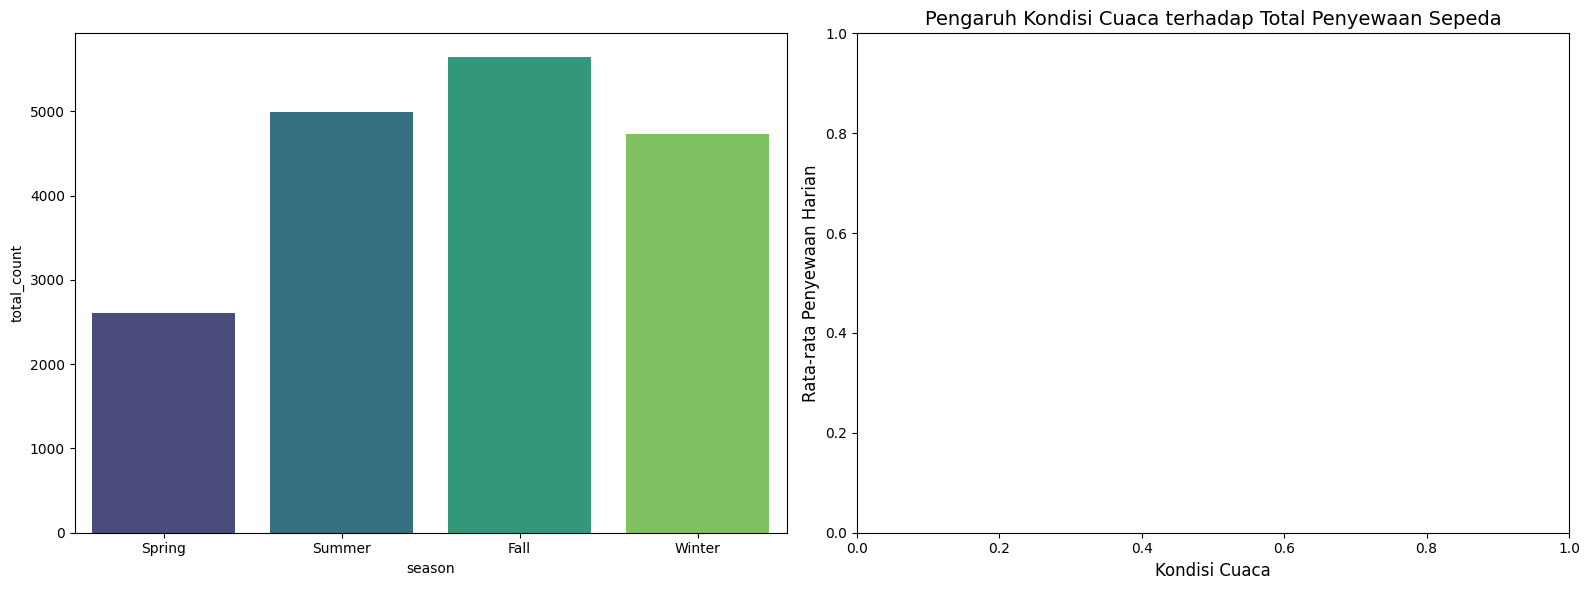

In [11]:
# Visualisasi Pengaruh Musim dan Kondisi Cuaca terhadap Total Penyewaan
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Subplot 1: Rata-rata Penyewaan Berdasarkan Musim
sns.barplot(
    x='season',
    y='total_count',
    data=day_df,
    ax=ax[0],
    palette='viridis',
    errorbar=None
)
ax[1].set_title('Pengaruh Kondisi Cuaca terhadap Total Penyewaan Sepeda', fontsize=14)
ax[1].set_xlabel('Kondisi Cuaca', fontsize=12)
ax[1].set_ylabel('Rata-rata Penyewaan Harian', fontsize=12)

plt.tight_layout()
plt.show()

### Pertanyaan 2:

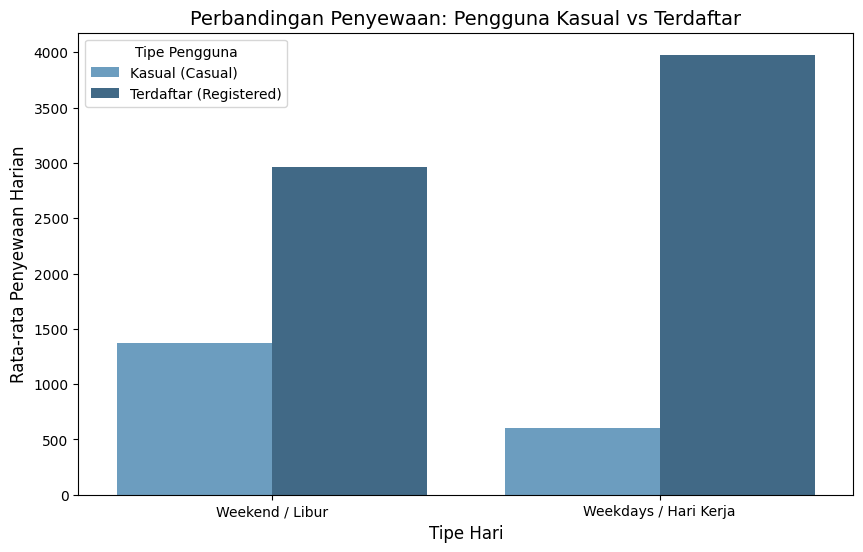

In [13]:
# Transformasi data (melt) untuk membuat Grouped Bar Chart perbandingan pengguna
melted_df = pd.melt(
    day_df,
    id_vars=['workingday'],
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='count'
)

# Ubah label 0 dan 1 menjadi teks deskriptif
melted_df['workingday'] = melted_df['workingday'].map({0: 'Weekend / Libur', 1: 'Weekdays / Hari Kerja'})

# Plotting Grouped Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x='workingday',
    y='count',
    hue='user_type',
    data=melted_df,
    palette='Blues_d',
    errorbar=None
)

plt.title('Perbandingan Penyewaan: Pengguna Kasual vs Terdaftar', fontsize=14)
plt.xlabel('Tipe Hari', fontsize=12)
plt.ylabel('Rata-rata Penyewaan Harian', fontsize=12)
plt.legend(title='Tipe Pengguna', labels=['Kasual (Casual)', 'Terdaftar (Registered)'])
plt.show()

**Insight:** (Opsional)
- Visualisasi Pertanyaan 1 (Musim & Cuaca): Musim Gugur (Fall) mencatatkan penyewaan tertinggi, diikuti oleh Musim Panas (Summer) dan Musim Dingin (Winter), sedangkan Musim Semi (Spring) paling rendah. Berdasarkan kondisi cuaca, pengguna sangat menyukai cuaca cerah/berawan (Clear/Partly Cloudy) dan angka penyewaan menurun drastis saat terjadi hujan ringan/salju (Light Snow/Rain).
- Visualisasi Pertanyaan 2 (Perilaku Pengguna): Pengguna terdaftar (registered) mendominasi penyewaan pada hari kerja untuk aktivitas mobilitas harian (commuting). Sebaliknya, pengguna kasual (casual) mengalami peningkatan signifikan pada akhir pekan dan hari libur untuk kegiatan rekreasi.

## Analisis Lanjutan (Opsional)

--- Ringkasan Pengelompokan Kategori Permintaan (Demand Level) ---


/tmp/ipykernel_785/3645392860.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  demand_summary = day_df.groupby('demand_category').agg({


demand_category       casual   registered total_count             
                          mean         mean       count         mean
0      Low Demand   255.808140  1603.825581         172  1859.633721
1   Medium Demand   803.382586  3687.403694         379  4490.786280
2     High Demand  1508.533333  5551.544444         180  7060.077778

/tmp/ipykernel_785/3645392860.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='demand_category', data=day_df, palette='Set2')


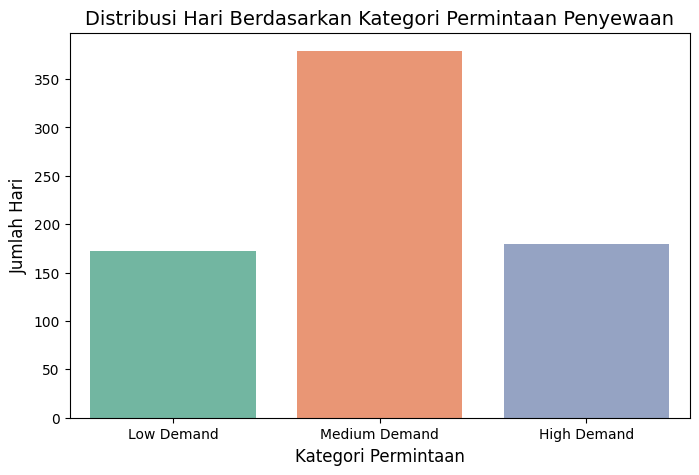

In [14]:
# Menerapkan Teknik Analisis Lanjutan: Binning / Manual Grouping (Clustering tanpa ML)
# Mengelompokkan hari berdasarkan tingkat permintaan penyewaan (total_count)
bins = [0, 3000, 6000, 10000]
labels = ['Low Demand', 'Medium Demand', 'High Demand']
day_df['demand_category'] = pd.cut(day_df['total_count'], bins=bins, labels=labels)

# Ringkasan statistik per kategori permintaan
demand_summary = day_df.groupby('demand_category').agg({
    'casual': 'mean',
    'registered': 'mean',
    'total_count': ['count', 'mean']
}).reset_index()

print("--- Ringkasan Pengelompokan Kategori Permintaan (Demand Level) ---")
display(demand_summary)

# Visualisasi Distribusi Kategori Permintaan
plt.figure(figsize=(8, 5))
sns.countplot(x='demand_category', data=day_df, palette='Set2')
plt.title('Distribusi Hari Berdasarkan Kategori Permintaan Penyewaan', fontsize=14)
plt.xlabel('Kategori Permintaan', fontsize=12)
plt.ylabel('Jumlah Hari', fontsize=12)
plt.show()

**Insight:** (Opsional)
- Hari operasional berhasil dikelompokkan menjadi 3 segmen utama: Low Demand (<= 3.000 penyewaan), Medium Demand (3.001 - 6.000 penyewaan), dan High Demand (> 6.000 penyewaan)
- Mayoritas hari operasional berada pada kategori Medium Demand (379 hari), diikuti High Demand (180 hari) dan Low Demand (172 hari).
- Pada hari bertekanan tinggi (High Demand), penyewaan oleh pengguna terdaftar (registered) melonjak tajam hingga rata-rata 5.551 penyewaan/hari, sedangkan pengguna kasual (casual) rata-rata 1.508 penyewaan/hari.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca dan musim berpengaruh signifikan terhadap tingkat penyewaan sepeda harian. Penyewaan tertinggi terjadi pada Musim Gugur (Fall) dengan rata-rata 5.644 penyewaan/hari dan saat cuaca/sedikit berawan (Clear/Partly Cloudy) dengan rata-rata 4.877 penyewaan/hari. Sebaliknya, penyewaan paling rendah terjadi pada Musim Semi (Spring) dengan rata-rata 2.604 penyewaan/hari serta saat terjadi hujan ringan/salju (light snow/rain) yang anjlok menjadi rata-rata 1.803 penyewaan/hari
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola penggunaan yang jelas antara kedua jenis pengguna. Pengguna terdaftar (*registered*) aktif di hari kerja (*workingday*) dengan rata-rata 3.978 penyewaan/hari untuk mobilitas rutin (*commuting*). Sementara pengguna kasual (*casual*) mengalami peningkatan signifikan pada akhir pekan dan hari libur nasional dengan rata-rata 1.371 penyewaan/hari untuk aktivitas rekreasi.
- ...

**Rekomendasi Action Item:**
 - **Manajemen Penjadwalan Perawatan & Stok Armada:** Lakukan perawatan rutin (*maintenance*) sepeda secara intensif pada Musim Semi dan saat cuaca buruk agar seluruh armada berada dalam kondisi optimal 100% menyambut puncak permintaan (*peak season*) di Musim Panas dan Musim Gugur.
- **Strategi Pemasaran Berkelanjutan (Commuter vs Recreational Pass):**
   - **Hari Kerja:** Sediakan paket langganan komuter bulanan/tahunan dengan fitur *cashback* atau diskon khusus untuk mempertahankan loyalitas pengguna terdaftar (*registered*).
   - **Akhir Pekan/Libur:** Sediakan paket *Weekend Pass* atau promo sewa harian rekreasi untuk menggaet lebih banyak pengguna kasual (*casual*).
-  **Redistribusi Logistik Stasiun Sepeda:** Lakukan penataan kembali (*redistribution*) unit sepeda ke stasiun yang berlokasi di area perkantoran/pusat bisnis pada pagi hari di hari kerja, serta alokasikan lebih banyak unit ke stasiun area taman/tempat wisata saat akhir pekan dan hari libur nasional.